# Day 5 — Exploratory data analysis: distributions, correlations and charts

Run each cell with **Shift + Enter**, from the top. We use the cleaned student dataset from Day 4, `student_data_clean.csv`; every table and chart here is computed from it.

## 1. Introduction to EDA

In [ ]:
# Get the datasets: Colab starts with an empty folder, so download the files the first time
import os
import urllib.request

BASE = "https://raw.githubusercontent.com/neerajb1/learnforge-notebooks/main/ai-ml-120/day-005/data/"
for name in ["student_data_clean.csv", "student_data_150.csv"]:   # 8 real students; 150 with synthetic ones
    if not os.path.exists(name):
        urllib.request.urlretrieve(BASE + name, name)

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.width", 120)    # print wide tables on one line

# Load the cleaned dataset from Day 4
df = pd.read_csv("student_data_clean.csv")
print(df.head())

  Student Class   Age  StudyHours  Attendance  PreviousScore  ExamScore  Passed
0      S1     A  10.0         1.0        60.0             40       35.0   False
1      S2     A  11.0         2.0        70.0             50       45.0   False
2      S3     B  11.0         3.0        80.0             60       55.0    True
3      S4     B  12.0         4.0        80.0             70       65.0    True
4      S5     B  11.0         3.0        95.0             80       75.0    True


In [ ]:
# Basic dataset overview
print("Shape:", df.shape)
df.info()          # info() prints its own report

Shape: (8, 8)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8 entries, 0 to 7
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Student        8 non-null      object 
 1   Class          8 non-null      object 
 2   Age            8 non-null      float64
 3   StudyHours     8 non-null      float64
 4   Attendance     8 non-null      float64
 5   PreviousScore  8 non-null      int64  
 6   ExamScore      8 non-null      float64
 7   Passed         8 non-null      bool   
dtypes: bool(1), float64(4), int64(1), object(2)
memory usage: 588.0+ bytes


In [ ]:
# Summary statistics of the numerical columns
print(df.describe().round(1))

        Age  StudyHours  Attendance  PreviousScore  ExamScore
count   8.0         8.0         8.0            8.0        8.0
mean   11.2         2.9        79.0           59.4       58.1
std     0.7         1.5        13.0           16.4       16.9
min    10.0         1.0        60.0           35.0       35.0
25%    11.0         1.8        68.8           47.5       43.8
50%    11.0         3.0        80.0           62.5       60.0
75%    12.0         4.0        90.5           71.2       71.2
max    12.0         5.0        95.0           80.0       80.0


In [ ]:
# Numerical and categorical columns
numerical = df.select_dtypes(include="number").columns.tolist()
categorical = df.select_dtypes(exclude="number").columns.tolist()
print("Numerical:", numerical)
print("Categorical:", categorical)
print()
print(df["Class"].value_counts().sort_index())

Numerical: ['Age', 'StudyHours', 'Attendance', 'PreviousScore', 'ExamScore']
Categorical: ['Student', 'Class', 'Passed']

Class
A          3
B          3
C          1
Unknown    1
Name: count, dtype: int64


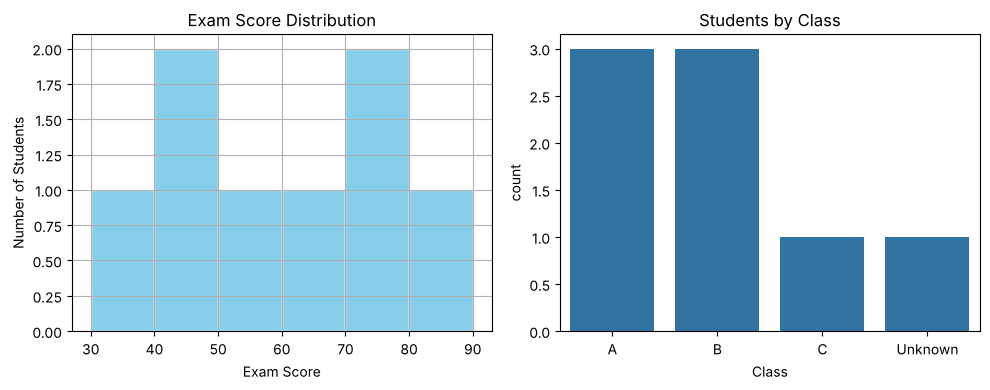

In [ ]:
# Your first charts: the exam score distribution and the students per class
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

df["ExamScore"].hist(bins=range(30, 91, 10), color="skyblue", edgecolor="white", ax=axes[0])
axes[0].set_title("Exam Score Distribution")
axes[0].set_xlabel("Exam Score")
axes[0].set_ylabel("Number of Students")

sns.countplot(x="Class", data=df, order=sorted(df["Class"].unique()), ax=axes[1])
axes[1].set_title("Students by Class")

plt.tight_layout()
plt.show()

## 2. Distributions of numerical data

In [ ]:
# Centre and spread of each numerical column
cols = ["Age", "StudyHours", "Attendance", "ExamScore"]
summary = pd.DataFrame({
    "mean": df[cols].mean(),
    "median": df[cols].median(),
    "min": df[cols].min(),
    "max": df[cols].max(),
    "range": df[cols].max() - df[cols].min(),
    "IQR": df[cols].quantile(0.75) - df[cols].quantile(0.25),
    "std": df[cols].std(),
}).round(1)
print(summary)

            mean  median   min   max  range   IQR   std
Age         11.2    11.0  10.0  12.0    2.0   1.0   0.7
StudyHours   2.9     3.0   1.0   5.0    4.0   2.2   1.5
Attendance  79.0    80.0  60.0  95.0   35.0  21.8  13.0
ExamScore   58.1    60.0  35.0  80.0   45.0  27.5  16.9


In [ ]:
# What a histogram counts: how many scores fall in each bin (range of values)
bins = range(30, 91, 10)
print(pd.cut(df["ExamScore"], bins=bins, right=False).value_counts().sort_index())

ExamScore
[30, 40)    1
[40, 50)    2
[50, 60)    1
[60, 70)    1
[70, 80)    2
[80, 90)    1
Name: count, dtype: int64


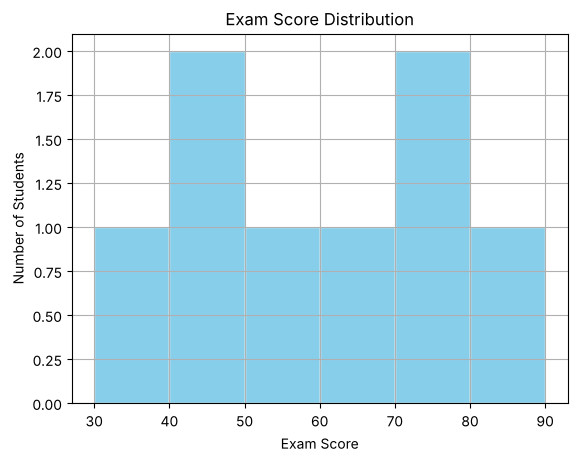

In [ ]:
# Histogram of exam scores
df["ExamScore"].hist(bins=range(30, 91, 10), color="skyblue", edgecolor="white")
plt.title("Exam Score Distribution")
plt.xlabel("Exam Score")
plt.ylabel("Number of Students")
plt.show()

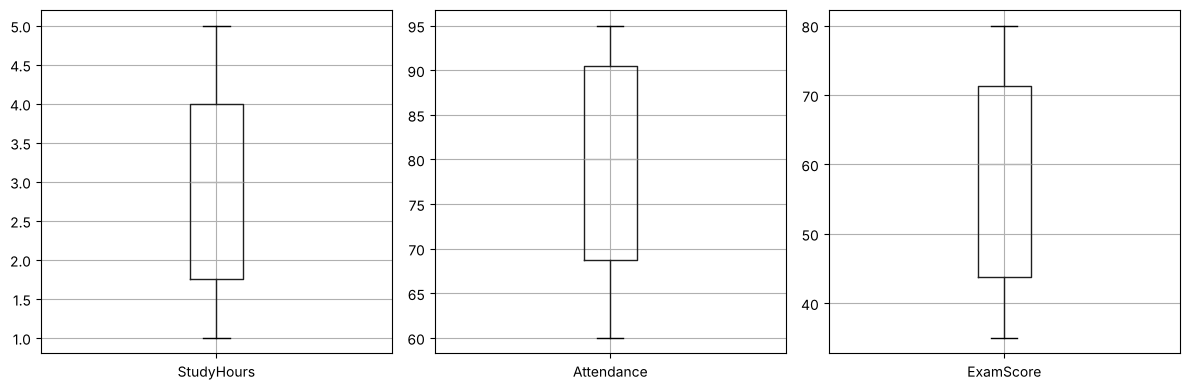

In [ ]:
# Box plots: one per column, because the columns have different units
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, col in zip(axes, ["StudyHours", "Attendance", "ExamScore"]):
    df.boxplot(column=col, ax=ax)
plt.tight_layout()
plt.show()

In [ ]:
# A density plot is a smoothed histogram: each score adds a small bell curve, and the curves are summed
from scipy.stats import gaussian_kde

kde = gaussian_kde(df["ExamScore"])                    # the same smoothing as seaborn's kdeplot
print("Bandwidth (width of each bell curve):", round(kde.factor * df["ExamScore"].std(), 1))
for score in [40, 60, 80]:
    print(f"Density at {score}: {kde(score)[0]:.4f}")

Bandwidth (width of each bell curve): 11.1
Density at 40: 0.0149
Density at 60: 0.0169
Density at 80: 0.0137


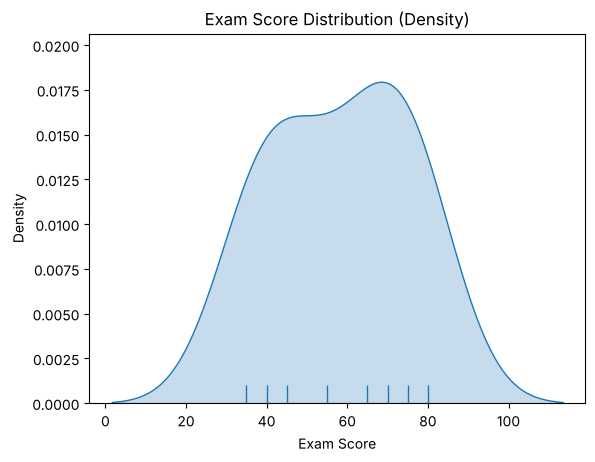

In [ ]:
# Density plot, with the real scores marked underneath
sns.kdeplot(df["ExamScore"], fill=True)
sns.rugplot(df["ExamScore"], height=0.05)
plt.title("Exam Score Distribution (Density)")
plt.xlabel("Exam Score")
plt.ylabel("Density")
plt.show()

In [ ]:
# Compare the distributions: shape and relative spread
compare = pd.DataFrame({
    "mean": df[cols].mean(),
    "median": df[cols].median(),
    "skew": df[cols].skew(),
    "std / mean": df[cols].std() / df[cols].mean(),   # spread relative to the typical value
}).round(2)
print(compare)
print("\nUnique values in Age:", sorted(df["Age"].unique().tolist()))

             mean  median  skew  std / mean
Age         11.25    11.0 -0.40        0.06
StudyHours   2.88     3.0 -0.09        0.51
Attendance  79.00    80.0 -0.23        0.16
ExamScore   58.12    60.0 -0.13        0.29

Unique values in Age: [10.0, 11.0, 12.0]


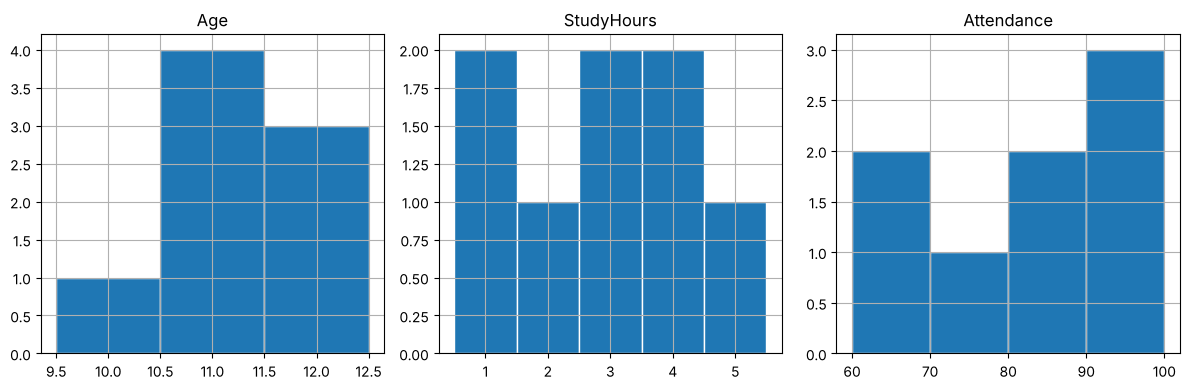

In [ ]:
# Histograms of the other numerical columns
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
df["Age"].hist(bins=[9.5, 10.5, 11.5, 12.5], ax=axes[0], edgecolor="white")
df["StudyHours"].hist(bins=[0.5, 1.5, 2.5, 3.5, 4.5, 5.5], ax=axes[1], edgecolor="white")
df["Attendance"].hist(bins=range(60, 101, 10), ax=axes[2], edgecolor="white")
for ax, col in zip(axes, ["Age", "StudyHours", "Attendance"]):
    ax.set_title(col)
plt.tight_layout()
plt.show()

## 3. Categorical data analysis (150 students: 8 real, 142 synthetic)

In [ ]:
# From here on: 150 students, the 8 real ones plus 142 synthetic ones (simulated data for practice)
students = pd.read_csv("student_data_150.csv")
print("Shape:", students.shape)
print(students["Source"].value_counts())

Shape: (150, 9)
Source
synthetic    142
original       8
Name: count, dtype: int64


In [ ]:
# Unique values: which categories exist, and how many
for col in ["Class", "Passed", "Source"]:
    print(f"{col}: {students[col].nunique()} values {sorted(students[col].unique().tolist())}")

Class: 4 values ['A', 'B', 'C', 'Unknown']
Passed: 2 values [False, True]
Source: 2 values ['original', 'synthetic']


In [ ]:
# Value counts: students in each class, and each class's share of all students
counts = students["Class"].value_counts()
percent = students["Class"].value_counts(normalize=True).mul(100).round(1)
print(pd.DataFrame({"Students": counts, "Percent": percent}))

         Students  Percent
Class                     
A              49     32.7
B              49     32.7
C              47     31.3
Unknown         5      3.3


In [ ]:
# Proportions: what share of students passed (ExamScore of 50 or more)?
print(students["Passed"].value_counts(normalize=True).mul(100).round(1))

Passed
True     70.7
False    29.3
Name: proportion, dtype: float64


In [ ]:
# Cross-tabulation: Class against Passed, with totals
print(pd.crosstab(students["Class"], students["Passed"], margins=True, margins_name="Total"))

Passed   False  True  Total
Class                      
A           14    35     49
B           12    37     49
C           16    31     47
Unknown      2     3      5
Total       44   106    150


In [ ]:
# Pass rate within each class: normalize="index" turns each row into percentages
print(pd.crosstab(students["Class"], students["Passed"], normalize="index").mul(100).round(1))

Passed   False  True 
Class                
A         28.6   71.4
B         24.5   75.5
C         34.0   66.0
Unknown   40.0   60.0


In [ ]:
# Attendance is a number; pd.cut turns it into categories (bands)
students["AttendanceBand"] = pd.cut(students["Attendance"], bins=[0, 70, 85, 101], right=False,
                                    labels=["Low (under 70%)", "Medium (70-84%)", "High (85% or more)"])
print(students["AttendanceBand"].value_counts().sort_index())
print()
print(pd.crosstab(students["AttendanceBand"], students["Passed"], normalize="index").mul(100).round(1))

AttendanceBand
Low (under 70%)       24
Medium (70-84%)       80
High (85% or more)    46
Name: count, dtype: int64

Passed              False  True 
AttendanceBand                  
Low (under 70%)      58.3   41.7
Medium (70-84%)      31.2   68.8
High (85% or more)   10.9   89.1


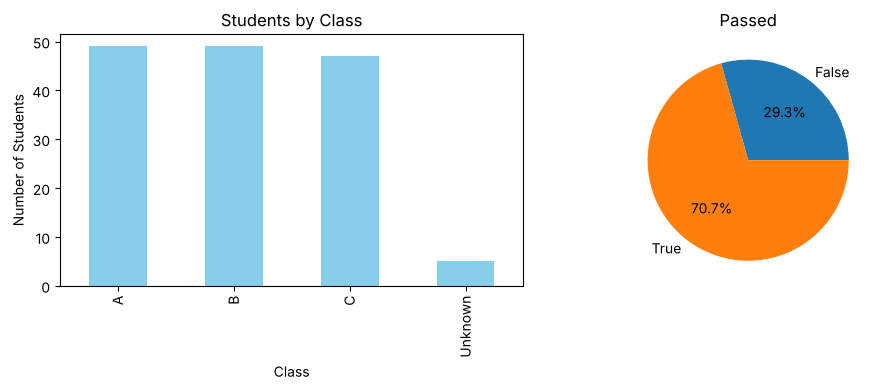

In [ ]:
# Bar chart and pie chart
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
students["Class"].value_counts().sort_index().plot(kind="bar", color="skyblue", ax=axes[0])
axes[0].set_title("Students by Class")
axes[0].set_xlabel("Class")
axes[0].set_ylabel("Number of Students")
students["Passed"].value_counts().sort_index().plot(kind="pie", autopct="%1.1f%%", ax=axes[1])
axes[1].set_title("Passed")
axes[1].set_ylabel("")
plt.tight_layout()
plt.show()

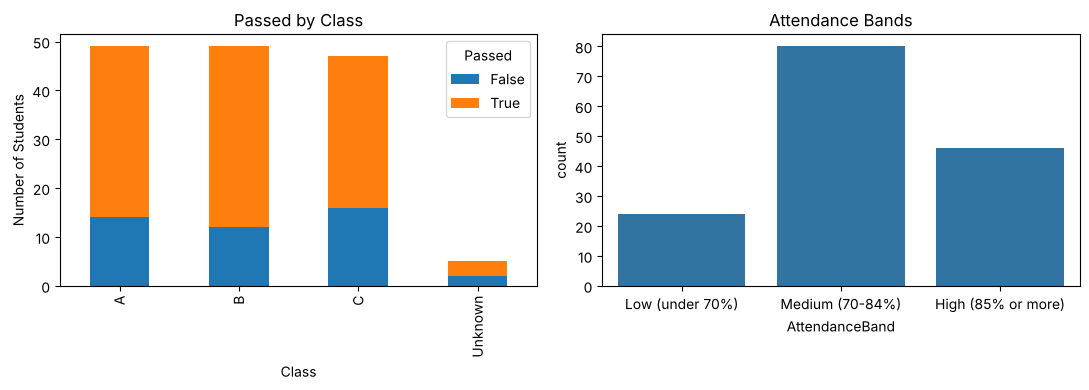

In [ ]:
# Stacked bar chart of the cross-tabulation, and a seaborn count plot of the attendance bands
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
pd.crosstab(students["Class"], students["Passed"]).plot(kind="bar", stacked=True, ax=axes[0])
axes[0].set_title("Passed by Class")
axes[0].set_ylabel("Number of Students")
sns.countplot(x="AttendanceBand", data=students, ax=axes[1])
axes[1].set_title("Attendance Bands")
plt.tight_layout()
plt.show()

## 4. Correlations and relationships (150 students: 8 real, 142 synthetic)

In [ ]:
# Correlation matrix of the numerical columns
numeric_df = students.select_dtypes(include="number")
corr = numeric_df.corr()
print(corr.round(2))

                Age  StudyHours  Attendance  PreviousScore  ExamScore
Age            1.00        0.10       -0.03           0.03       0.08
StudyHours     0.10        1.00        0.26           0.27       0.61
Attendance    -0.03        0.26        1.00           0.09       0.38
PreviousScore  0.03        0.27        0.09           1.00       0.54
ExamScore      0.08        0.61        0.38           0.54       1.00


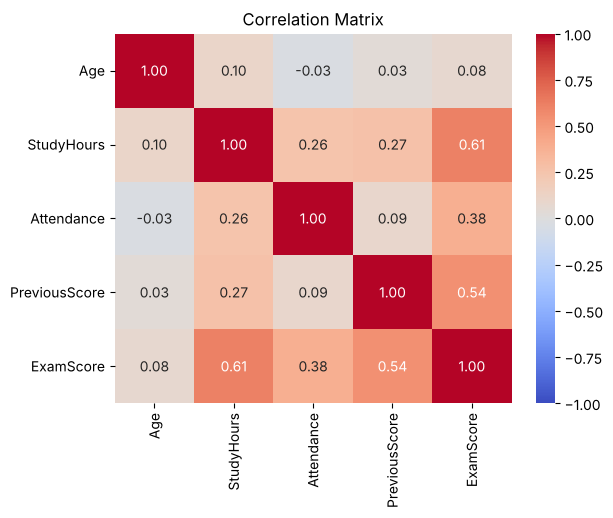

In [ ]:
# Heatmap of the correlation matrix
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation Matrix")
plt.show()

In [ ]:
# Every pair of columns once, from the most negative to the most positive correlation
pairs = corr.stack()                                                               # (column, column) -> r
pairs = pairs[pairs.index.get_level_values(0) < pairs.index.get_level_values(1)]   # each pair once
print(pairs.sort_values().round(2))

Age            Attendance      -0.03
               PreviousScore    0.03
               ExamScore        0.08
Attendance     PreviousScore    0.09
Age            StudyHours       0.10
Attendance     StudyHours       0.26
PreviousScore  StudyHours       0.27
Attendance     ExamScore        0.38
ExamScore      PreviousScore    0.54
               StudyHours       0.61
dtype: float64


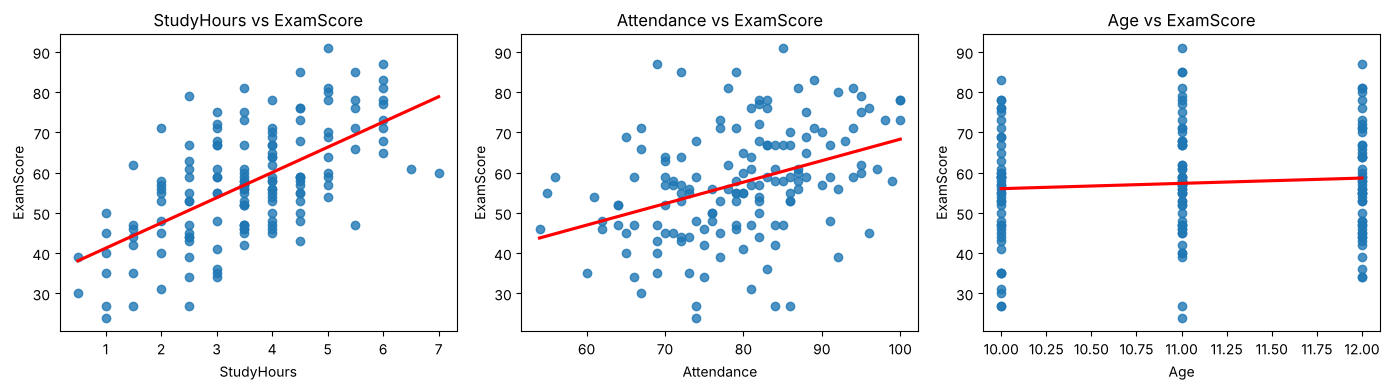

In [ ]:
# Scatter plots with trend lines (regression plots)
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, col in zip(axes, ["StudyHours", "Attendance", "Age"]):
    sns.regplot(data=students, x=col, y="ExamScore", ci=None, ax=ax, line_kws={"color": "red"})
    ax.set_title(f"{col} vs ExamScore")
plt.tight_layout()
plt.show()

In [ ]:
# The trend line a regression plot draws: least squares, ExamScore = intercept + slope x column
import numpy as np

for col in ["StudyHours", "Attendance", "Age"]:
    slope, intercept = np.polyfit(students[col], students["ExamScore"], 1)
    r = students[col].corr(students["ExamScore"])
    print(f"{col:<11} r = {r:.2f}   slope = {slope:.2f} points per unit   intercept = {intercept:.1f}")

StudyHours  r = 0.61   slope = 6.27 points per unit   intercept = 35.0
Attendance  r = 0.38   slope = 0.53 points per unit   intercept = 14.9
Age         r = 0.08   slope = 1.31 points per unit   intercept = 42.9


In [ ]:
# The same correlation in the 8 real students and in all 150
real = students[students["Source"] == "original"]
for name, part in [("8 real students", real), ("All 150 students", students)]:
    print(f"{name:<17} StudyHours vs ExamScore: r = {part['StudyHours'].corr(part['ExamScore']):.2f}")

8 real students   StudyHours vs ExamScore: r = 0.92
All 150 students  StudyHours vs ExamScore: r = 0.61


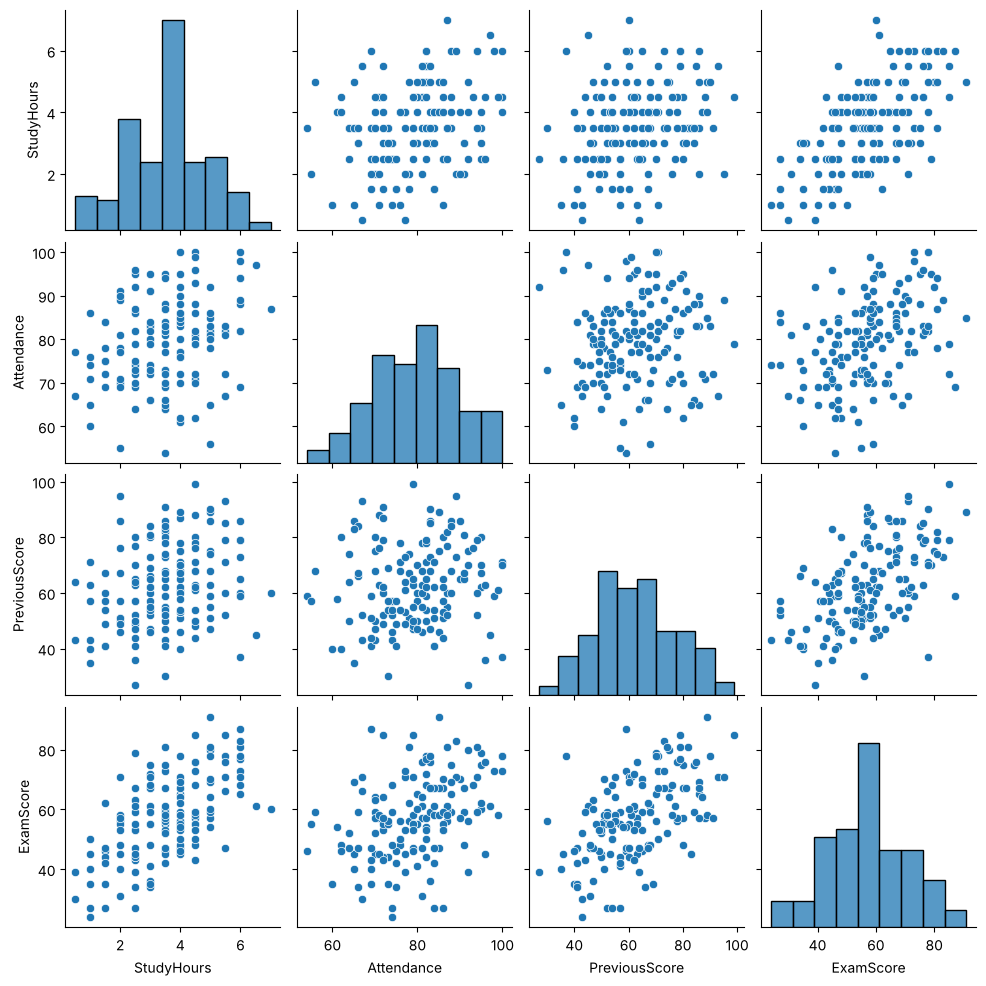

In [ ]:
# Pair plot: every pair of numerical columns at once (histograms on the diagonal)
sns.pairplot(students[["StudyHours", "Attendance", "PreviousScore", "ExamScore"]])
plt.show()

## 5. Visualization best practices (150 students: 8 real, 142 synthetic)

In [ ]:
# How a cut-off axis exaggerates: pass rates by class, and their bars drawn from 0 or from 60
rates = students.groupby("Class")["Passed"].mean().mul(100).round(1)
print(rates.to_string())
b, c = rates["B"], rates["C"]
print(f"\nB vs C, real ratio: {b / c:.2f}x")
print(f"Bar heights with the axis starting at 60: {(b - 60) / (c - 60):.2f}x")

Class
A          71.4
B          75.5
C          66.0
Unknown    60.0

B vs C, real ratio: 1.14x
Bar heights with the axis starting at 60: 2.58x


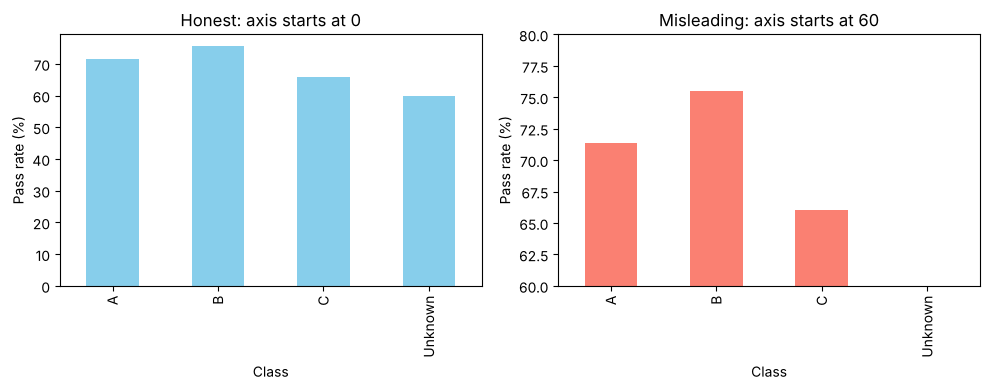

In [ ]:
# The same pass rates, honest (axis from 0) and misleading (axis from 60)
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
rates.plot(kind="bar", ax=axes[0], color="skyblue", title="Honest: axis starts at 0")
rates.plot(kind="bar", ax=axes[1], color="salmon", title="Misleading: axis starts at 60")
axes[1].set_ylim(60, 80)
for ax in axes:
    ax.set_ylabel("Pass rate (%)")
plt.tight_layout()
plt.show()

In [ ]:
# Would colouring the scatter plot by class help? Only if the classes differ
print(students.groupby("Class")[["StudyHours", "ExamScore"]].mean().round(1))

         StudyHours  ExamScore
Class                         
A               3.6       58.2
B               3.6       56.8
C               3.6       57.0
Unknown         2.8       57.8


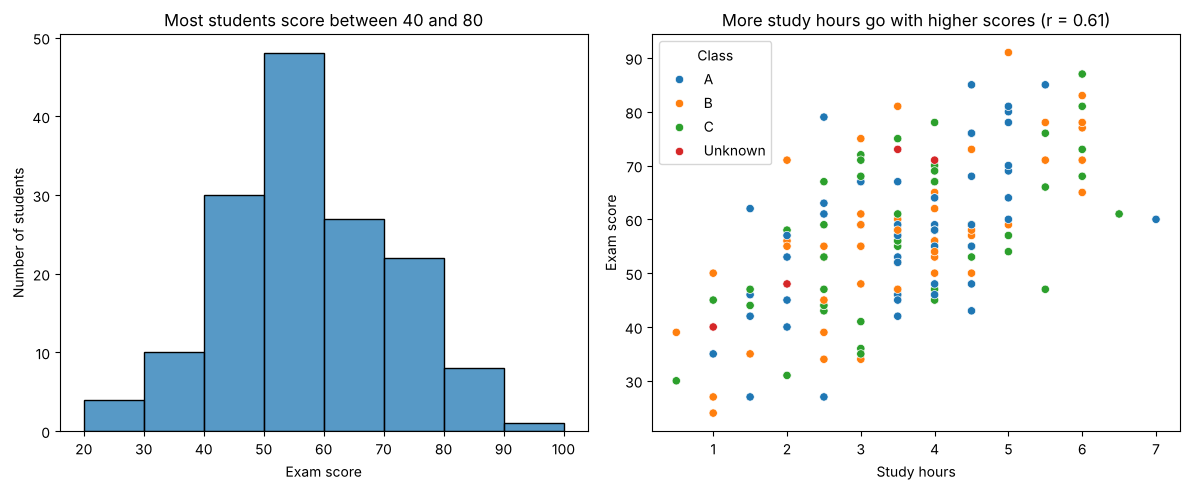

In [ ]:
# Multiple plots: a histogram and a scatter plot side by side, with clear titles and labels
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.histplot(data=students, x="ExamScore", bins=range(20, 101, 10), ax=axes[0])
axes[0].set_title("Most students score between 40 and 80")
axes[0].set_xlabel("Exam score")
axes[0].set_ylabel("Number of students")

sns.scatterplot(data=students, x="StudyHours", y="ExamScore", hue="Class", ax=axes[1])
axes[1].set_title("More study hours go with higher scores (r = 0.61)")
axes[1].set_xlabel("Study hours")
axes[1].set_ylabel("Exam score")

plt.tight_layout()
plt.show()

In [ ]:
# A data story starts with a question: do students who study more score higher?
hours = pd.cut(students["StudyHours"], bins=[0, 2, 4, 8], labels=["Up to 2 h", "2.5 to 4 h", "4.5 h or more"])
story = students.groupby(hours, observed=True)["ExamScore"].agg(["count", "mean"]).round(1)
print(story)

               count  mean
StudyHours                
Up to 2 h         25  44.3
2.5 to 4 h        81  56.0
4.5 h or more     44  67.4


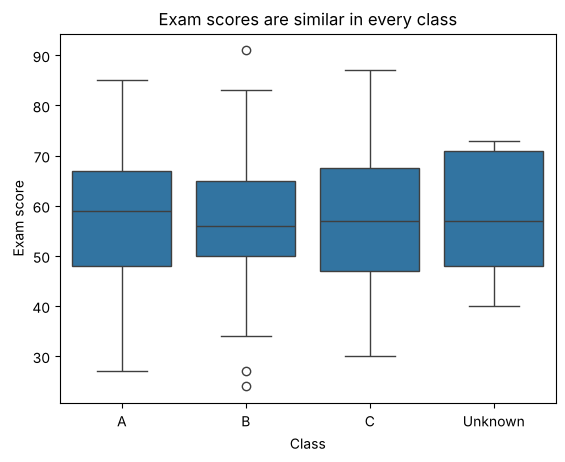

In [ ]:
# Compare exam scores across classes with a box plot
sns.boxplot(data=students, x="Class", y="ExamScore", order=["A", "B", "C", "Unknown"])
plt.title("Exam scores are similar in every class")
plt.ylabel("Exam score")
plt.show()

## 6. Mini project: EDA of student performance (150 students: 8 real, 142 synthetic)

In [ ]:
# Mini project: load the expanded dataset and inspect its structure (df now holds all 150 students)
df = pd.read_csv("student_data_150.csv")
print("Shape:", df.shape)
print("Columns:", df.columns.tolist())
print(df["Source"].value_counts().to_string())
print()
for col in ["Age", "StudyHours", "Attendance", "PreviousScore", "ExamScore"]:
    print(f"{col:<14} {df[col].min():>5} to {df[col].max()}")

Shape: (150, 9)
Columns: ['Student', 'Class', 'Age', 'StudyHours', 'Attendance', 'PreviousScore', 'ExamScore', 'Passed', 'Source']
Source
synthetic    142
original       8

Age             10.0 to 12.0
StudyHours       0.5 to 7.0
Attendance      54.0 to 100.0
PreviousScore     27 to 99
ExamScore       24.0 to 91.0


In [ ]:
# Class sizes, and exam scores by class
print(df["Class"].value_counts().to_string())
print()
print(df.groupby("Class")["ExamScore"].agg(["count", "mean", "median", "std"]).round(1))

Class
A          49
B          49
C          47
Unknown     5

         count  mean  median   std
Class                             
A           49  58.2    59.0  14.0
B           49  56.8    56.0  14.4
C           47  57.0    57.0  13.5
Unknown      5  57.8    57.0  14.3


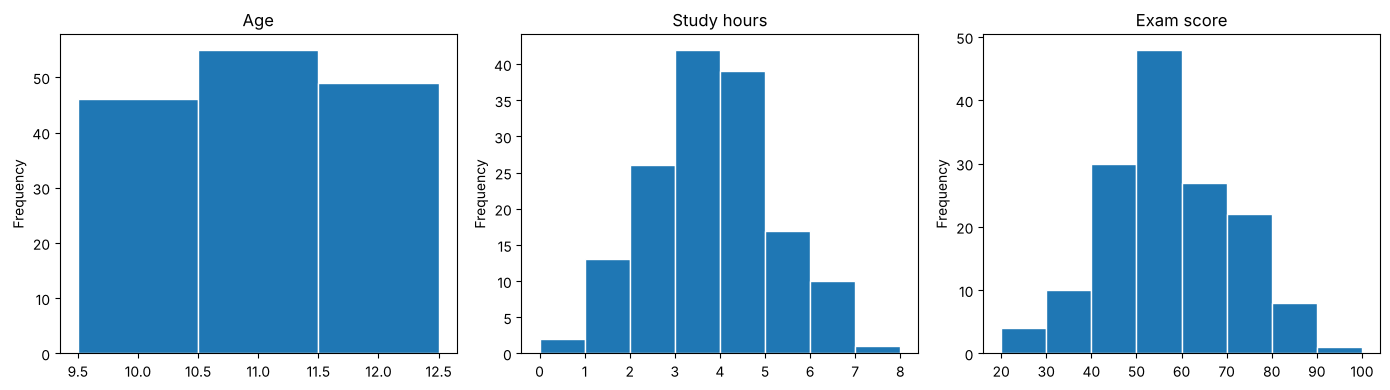

In [ ]:
# Histograms of Age, StudyHours and ExamScore
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
df["Age"].plot(kind="hist", bins=[9.5, 10.5, 11.5, 12.5], ax=axes[0], edgecolor="white", title="Age")
df["StudyHours"].plot(kind="hist", bins=range(0, 9), ax=axes[1], edgecolor="white", title="Study hours")
df["ExamScore"].plot(kind="hist", bins=range(20, 101, 10), ax=axes[2], edgecolor="white", title="Exam score")
plt.tight_layout()
plt.show()

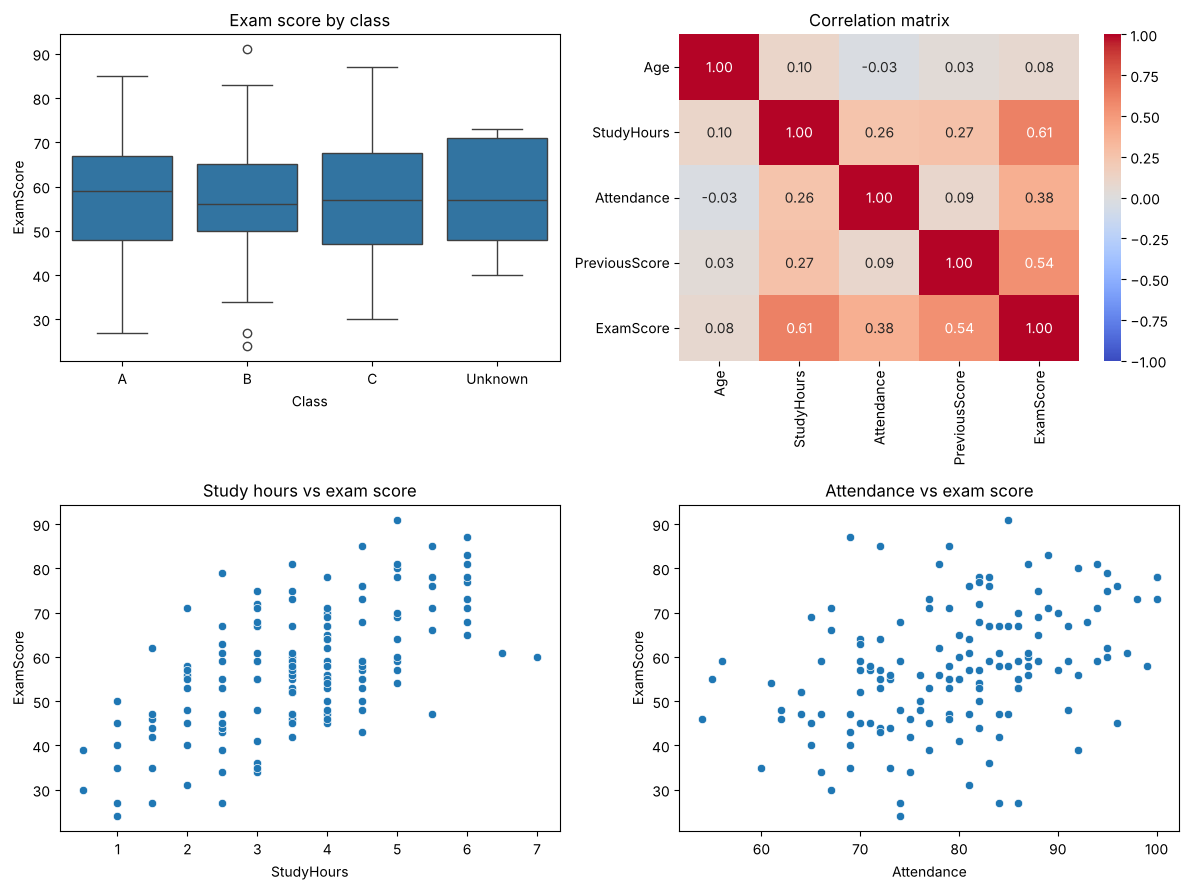

In [ ]:
# Exam scores across classes, the correlation heatmap, and two scatter plots
fig, axes = plt.subplots(2, 2, figsize=(12, 9))
sns.boxplot(data=df, x="Class", y="ExamScore", order=["A", "B", "C", "Unknown"], ax=axes[0, 0])
axes[0, 0].set_title("Exam score by class")
numeric = df.select_dtypes(include="number")
sns.heatmap(numeric.corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=axes[0, 1])
axes[0, 1].set_title("Correlation matrix")
sns.scatterplot(data=df, x="StudyHours", y="ExamScore", ax=axes[1, 0])
axes[1, 0].set_title("Study hours vs exam score")
sns.scatterplot(data=df, x="Attendance", y="ExamScore", ax=axes[1, 1])
axes[1, 1].set_title("Attendance vs exam score")
plt.tight_layout()
plt.show()

In [ ]:
# Unusual observations: values outside 1.5 x IQR of their column
for col in ["Age", "StudyHours", "Attendance", "PreviousScore", "ExamScore"]:
    q1, q3 = df[col].quantile([0.25, 0.75])
    low, high = q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)
    flagged = df[(df[col] < low) | (df[col] > high)]
    print(f"{col:<14} outside {low:.1f} to {high:.1f}: {flagged['Student'].tolist()} {flagged[col].tolist()}")

Age            outside 7.0 to 15.0: [] []
StudyHours     outside -0.5 to 7.5: [] []
Attendance     outside 51.0 to 107.0: [] []
PreviousScore  outside 20.5 to 104.5: [] []
ExamScore      outside 17.0 to 97.0: [] []


In [ ]:
# Answers to the project questions, computed from the data
sizes = df["Class"].value_counts()
means = df.groupby("Class")["ExamScore"].mean().round(1)
corr = df.select_dtypes(include="number").corr()
pairs = corr.stack()
pairs = pairs[pairs.index.get_level_values(0) < pairs.index.get_level_values(1)]
top = pairs.abs().idxmax()
print("1. Most students:", ", ".join(sizes[sizes == sizes.max()].index), f"({sizes.max()} each)")
print("2. Highest average exam score:", means.idxmax(), means.max(), "| range across classes:", means.min(), "to", means.max())
print(f"3. Exam scores: mean {df['ExamScore'].mean():.1f}, median {df['ExamScore'].median():.1f}, "
      f"skew {df['ExamScore'].skew():.2f}, {df['ExamScore'].between(40, 79).mean():.0%} between 40 and 79")
print(f"4. Strongest correlation: {top[0]} and {top[1]}, r = {pairs[top]:.2f}")

1. Most students: A, B (49 each)
2. Highest average exam score: A 58.2 | range across classes: 56.8 to 58.2
3. Exam scores: mean 57.4, median 57.0, skew -0.01, 85% between 40 and 79
4. Strongest correlation: ExamScore and StudyHours, r = 0.61
